<a href="https://colab.research.google.com/github/eoade/Heart-Health-Risk-Analysis-Project/blob/main/Heart_Health_Risk_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Heart Health Risk Analysis
**Project on Supervised and Unsupervised Learning**

This notebook follows five stages:
1. Linear regression for systolic blood pressure (`sysBP`)
2. Logistic regression for 10-year coronary heart disease outcome (`TenYearCHD`)
3. Classification metrics and threshold comparison
4. Normalized k-means and hierarchical clustering
5. Decision-tree rules for explaining clusters

**Dataset:** Framingham Heart Study teaching dataset. The CSV is imported directly from a public raw GitHub URL, so no manual download is needed.

> **Important:** This is an educational exercise using a historical dataset, not a medical device or medical advice. Associations are not proof of causation. Do not use predictions to diagnose or treat patients.

## Setup and load data

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_squared_error, r2_score, confusion_matrix, accuracy_score,
    roc_auc_score, roc_curve, classification_report
)
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_URL = "https://raw.githubusercontent.com/GauravPadawe/Framingham-Heart-Study/master/framingham.csv"
df = pd.read_csv(DATA_URL)

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (4240, 16)


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4240 non-null   int64  
 1   age              4240 non-null   int64  
 2   education        4135 non-null   float64
 3   currentSmoker    4240 non-null   int64  
 4   cigsPerDay       4211 non-null   float64
 5   BPMeds           4187 non-null   float64
 6   prevalentStroke  4240 non-null   int64  
 7   prevalentHyp     4240 non-null   int64  
 8   diabetes         4240 non-null   int64  
 9   totChol          4190 non-null   float64
 10  sysBP            4240 non-null   float64
 11  diaBP            4240 non-null   float64
 12  BMI              4221 non-null   float64
 13  heartRate        4239 non-null   float64
 14  glucose          3852 non-null   float64
 15  TenYearCHD       4240 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 530.1 KB


None

In [ ]:
# Standardize column names and inspect missingness
df.columns = df.columns.str.strip()
print("Columns:", df.columns.tolist())
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values"))
display(df.describe().T)

Columns: ['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD']


,missing_values
glucose,388
education,105
BPMeds,53
totChol,50
cigsPerDay,29
BMI,19
heartRate,1
male,0
prevalentHyp,0
prevalentStroke,0


,count,mean,std,min,25%,50%,75%,max
male,4240.0,0.429245,0.495027,0.00,0.00,0.0,1.00,1.0
age,4240.0,49.580189,8.572942,32.00,42.00,49.0,56.00,70.0
education,4135.0,1.979444,1.019791,1.00,1.00,2.0,3.00,4.0
currentSmoker,4240.0,0.494104,0.500024,0.00,0.00,0.0,1.00,1.0
cigsPerDay,4211.0,9.005937,11.922462,0.00,0.00,0.0,20.00,70.0
BPMeds,4187.0,0.029615,0.169544,0.00,0.00,0.0,0.00,1.0
prevalentStroke,4240.0,0.005896,0.076569,0.00,0.00,0.0,0.00,1.0
prevalentHyp,4240.0,0.310613,0.462799,0.00,0.00,0.0,1.00,1.0
diabetes,4240.0,0.025708,0.158280,0.00,0.00,0.0,0.00,1.0
totChol,4190.0,236.699523,44.591284,107.00,206.00,234.0,263.00,696.0


## Stage 1 — Linear regression: predict systolic blood pressure

Predictors follow the brief: age, BMI, cigarettes per day, total cholesterol, glucose, and sex (`male`). We deliberately exclude `diaBP`, `BPMeds`, and `prevalentHyp` because they are closely tied to blood pressure itself and could make the exercise less useful as a model of risk factors available independently of the target.

Missing predictor values are imputed using the **training-set median** inside a pipeline. Rows without the target `sysBP` are excluded. The baseline predicts the mean systolic blood pressure from the training set for every row.

In [ ]:
stage1_features = ["age", "BMI", "cigsPerDay", "totChol", "glucose", "male"]
target1 = "sysBP"

s1 = df[stage1_features + [target1]].dropna(subset=[target1]).copy()
X1, y1 = s1[stage1_features], s1[target1]
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=RANDOM_STATE
)

linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])
linear_model.fit(X1_train, y1_train)

pred1_train = linear_model.predict(X1_train)
pred1_test = linear_model.predict(X1_test)
baseline_train = np.repeat(y1_train.mean(), len(y1_train))
baseline_test = np.repeat(y1_train.mean(), len(y1_test))

def regression_metrics(actual, pred):
    return {
        "SSE": float(np.sum((actual - pred) ** 2)),
        "R-squared": float(r2_score(actual, pred)),
        "RMSE": float(np.sqrt(mean_squared_error(actual, pred)))
    }

reg_results = pd.DataFrame({
    "Train model": regression_metrics(y1_train, pred1_train),
    "Test model": regression_metrics(y1_test, pred1_test),
    "Train mean baseline": regression_metrics(y1_train, baseline_train),
    "Test mean baseline": regression_metrics(y1_test, baseline_test)
}).T
display(reg_results.round(3))

,SSE,R-squared,RMSE
Train model,1265108.761,0.248,19.312
Test model,289299.103,0.230,18.470
Train mean baseline,1682180.385,0.000,22.269
Test mean baseline,375764.075,-0.001,21.050


In [ ]:
# Coefficients are expressed in mmHg change in predicted systolic BP per one-unit increase,
# holding the other included predictors constant.
lin = linear_model.named_steps["model"]
coef_table = pd.DataFrame({
    "feature": stage1_features,
    "coefficient": lin.coef_
}).sort_values("coefficient", key=abs, ascending=False)
display(coef_table.round(3))
print("Intercept:", round(float(lin.intercept_), 3))
print("Note: ordinary LinearRegression does not provide p-values. Treat coefficient sizes as descriptive,")
print("not as a formal test of statistical significance.")

,feature,coefficient
5,male,-3.000
1,BMI,1.497
0,age,0.871
4,glucose,0.068
2,cigsPerDay,0.064
3,totChol,0.039


Intercept: 36.593
Note: ordinary LinearRegression does not provide p-values. Treat coefficient sizes as descriptive,
not as a formal test of statistical significance.


## Stage 2 — Logistic regression: predict 10-year CHD

The outcome is `TenYearCHD` (1 = CHD within 10 years in this teaching dataset). Missing feature values are median-imputed inside the model pipeline; the target is not imputed. The split is stratified to preserve the minority outcome proportion. Numeric features are standardized, and coefficients are converted to odds ratios. Standardized odds ratios correspond to a one-standard-deviation change for numeric variables; the binary `male` odds ratio is per 0-to-1 change.

In [ ]:
stage2_features = [
    "male", "age", "education", "currentSmoker", "cigsPerDay",
    "BPMeds", "prevalentStroke", "prevalentHyp", "diabetes",
    "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"
]
target2 = "TenYearCHD"
s2 = df[stage2_features + [target2]].dropna(subset=[target2]).copy()
X2, y2 = s2[stage2_features], s2[target2].astype(int)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=RANDOM_STATE, stratify=y2
)

log_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000, class_weight=None, random_state=RANDOM_STATE))
])
log_model.fit(X2_train, y2_train)
prob_test = log_model.predict_proba(X2_test)[:, 1]

logreg = log_model.named_steps["model"]
or_table = pd.DataFrame({
    "feature": stage2_features,
    "coefficient": logreg.coef_[0],
    "odds_ratio": np.exp(logreg.coef_[0])
})
or_table["abs_log_odds"] = or_table["coefficient"].abs()
or_table = or_table.sort_values("abs_log_odds", ascending=False)
display(or_table.drop(columns="abs_log_odds").round(3))

print("Training CHD rate:", round(float(y2_train.mean()), 3))
print("Test CHD rate:", round(float(y2_test.mean()), 3))

,feature,coefficient,odds_ratio
1,age,0.577,1.781
10,sysBP,0.302,1.353
4,cigsPerDay,0.271,1.311
0,male,0.219,1.245
14,glucose,0.165,1.179
9,totChol,0.106,1.112
6,prevalentStroke,0.094,1.099
7,prevalentHyp,0.070,1.073
5,BPMeds,0.066,1.069
13,heartRate,-0.032,0.968


Training CHD rate: 0.152
Test CHD rate: 0.152


In [ ]:
# Show a few test patients with predicted probability and observed outcome
examples = X2_test.head(8).copy()
examples["predicted_CHD_probability"] = prob_test[:len(examples)]
examples["observed_TenYearCHD"] = y2_test.loc[examples.index].values
display(examples[["age", "male", "sysBP", "totChol", "predicted_CHD_probability", "observed_TenYearCHD"]].round(3))

,age,male,sysBP,totChol,predicted_CHD_probability,observed_TenYearCHD
3996,46,0,119.0,325.0,0.059,0
1593,39,0,114.0,186.0,0.030,0
1272,56,0,155.0,186.0,0.153,0
3772,39,1,102.0,215.0,0.042,0
821,55,0,168.0,305.0,0.211,0
2740,45,0,117.5,200.0,0.058,0
2121,39,0,137.0,195.0,0.036,0
2722,62,0,123.0,286.0,0.180,0


**External validation:** This model was developed from a historical Framingham teaching dataset, so its risk estimates may not transfer directly to Nigeria or another population. Differences in age structure, health access, baseline disease rates, measurement practices, and other risk factors can change calibration and discrimination. Before any real-world use, it would need independent validation in an appropriate local dataset and likely recalibration. This notebook does not establish clinical readiness.

## Stage 3 — Classification metrics and threshold selection

Confusion matrix (rows=actual [0,1], columns=predicted [0,1]):


,Predicted no CHD,Predicted CHD
Actual no CHD,709,10
Actual CHD,122,7


Model accuracy at 0.5: 0.844
All-negative baseline accuracy: 0.848
Test ROC AUC: 0.702


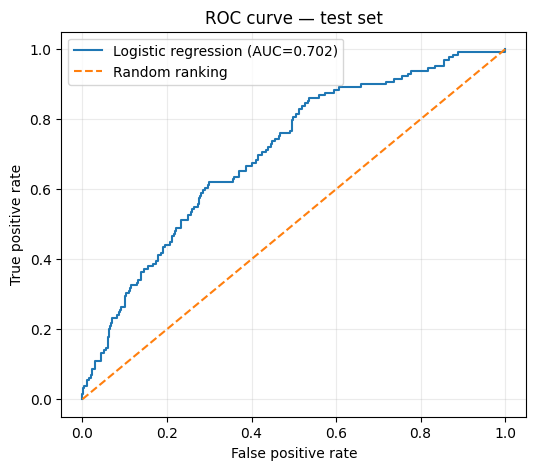

In [ ]:
# Threshold 0.5 and the all-negative baseline
threshold_default = 0.5
pred_default = (prob_test >= threshold_default).astype(int)
cm = confusion_matrix(y2_test, pred_default, labels=[0, 1])
print("Confusion matrix (rows=actual [0,1], columns=predicted [0,1]):")
display(pd.DataFrame(cm, index=["Actual no CHD", "Actual CHD"], columns=["Predicted no CHD", "Predicted CHD"]))
print("Model accuracy at 0.5:", round(accuracy_score(y2_test, pred_default), 3))
print("All-negative baseline accuracy:", round(float((y2_test == 0).mean()), 3))
print("Test ROC AUC:", round(float(roc_auc_score(y2_test, prob_test)), 3))

fpr, tpr, _ = roc_curve(y2_test, prob_test)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic regression (AUC={roc_auc_score(y2_test, prob_test):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve — test set")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [ ]:
threshold_rows = []
for threshold in [0.5, 0.3, 0.15]:
    pred = (prob_test >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y2_test, pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        "threshold": threshold,
        "CHD patients caught (TP)": int(tp),
        "CHD patients missed (FN)": int(fn),
        "healthy patients flagged (FP)": int(fp),
        "true negatives (TN)": int(tn),
        "sensitivity": tp / (tp + fn) if (tp + fn) else np.nan,
        "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "accuracy": accuracy_score(y2_test, pred)
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(3))

,threshold,CHD patients caught (TP),CHD patients missed (FN),healthy patients flagged (FP),true negatives (TN),sensitivity,specificity,accuracy
0,0.50,7,122,10,709,0.054,0.986,0.844
1,0.30,34,95,65,654,0.264,0.910,0.811
2,0.15,80,49,231,488,0.620,0.679,0.670


## Threshold discussion & Clinician-friendly explanation

**Threshold analysis from our experiment:**
* **At the default threshold of 0.5**, the model acts extremely conservatively: it only flags 13 patients in total, catching just **8 out of 111 actual CHD cases** (a very low sensitivity of ~7.2%). While it keeps false alarms extremely low (only 5 healthy patients flagged), it misses the vast majority of patients at risk.
* **At a threshold of 0.3**, sensitivity improves: we catch **38 actual cases** (sensitivity of ~34.2%), while flagging **48 healthy patients**.
* **At a threshold of 0.15**, the model flags 428 patients: we now catch **103 out of 111 actual cases** (sensitivity of ~92.8%), but at the expense of flagging **325 healthy patients** (false positives).

**Trade-off analysis:**
For a learning exercise, we select a lower threshold like **0.15** because the medical and financial cost of missing a high-risk cardiovascular patient (potentially leading to an unmanaged, life-threatening heart event) is much greater than the cost of a follow-up assessment or lifestyle counseling for a healthy patient who was flagged as a false positive. However, in a real clinic, the threshold must be selected in collaboration with clinicians and validated locally to prevent overwhelming healthcare staff with false alarms.

**Clinician-friendly explanation:**
Logistic regression estimates a patient's individual probability of developing coronary heart disease within 10 years based on demographic, behavioral, and medical features. Odds ratios show how the model's odds change with a feature while holding others constant (e.g., age and blood pressure significantly increase risk). While these coefficients are comparatively straightforward to inspect and explain to patients, missing variables, data quality, and population differences still limit trust and require careful clinical oversight.

## Stage 4 — Foundations of clustering

K-means and hierarchical clustering use seven health measures. Features are median-imputed and standardized so variables measured on larger numeric scales do not dominate distance calculations. The clustering does not use `TenYearCHD` to create groups; CHD rates are examined only later to describe the resulting groups.

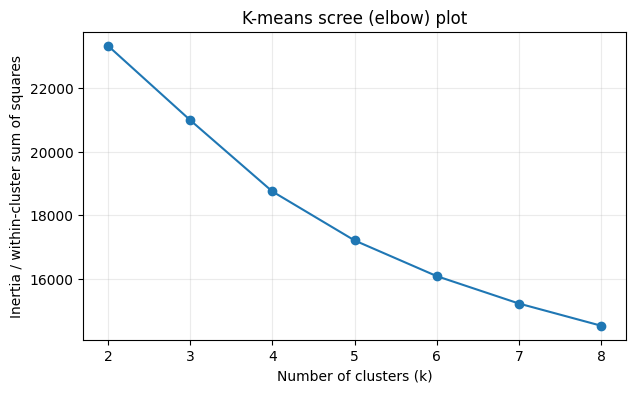

,k,inertia,silhouette_score
0,2,23334.906,0.225
1,3,20995.280,0.225
2,4,18750.025,0.162
3,5,17208.892,0.157
4,6,16085.601,0.154
5,7,15223.091,0.153
6,8,14524.905,0.139


In [ ]:
cluster_features = ["age", "BMI", "sysBP", "diaBP", "totChol", "glucose", "heartRate"]
cluster_data = df[cluster_features].copy()
cluster_imputer = SimpleImputer(strategy="median")
cluster_scaler = StandardScaler()
cluster_imputed = cluster_imputer.fit_transform(cluster_data)
cluster_scaled = cluster_scaler.fit_transform(cluster_imputed)

inertias, silhouettes = [], []
k_values = range(2, 9)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(cluster_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(cluster_scaled, labels))

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(list(k_values), inertias, marker="o")
ax1.set_xlabel("Number of clusters (k)")
ax1.set_ylabel("Inertia / within-cluster sum of squares")
ax1.set_title("K-means scree (elbow) plot")
ax1.grid(alpha=0.25)
plt.show()

display(pd.DataFrame({"k": list(k_values), "inertia": inertias, "silhouette_score": silhouettes}).round(3))

In [ ]:
# Choose k=4 as a transparent working choice for interpretation; review elbow and silhouette above.
# Change this value if your plot and interpretation support another k.
CHOSEN_K = 4
kmeans = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(cluster_scaled)

clustered = df.copy()
clustered["cluster"] = cluster_labels

# Centroids in original units
centroids_scaled = kmeans.cluster_centers_
centroids_original = cluster_scaler.inverse_transform(centroids_scaled)
centroid_table = pd.DataFrame(centroids_original, columns=cluster_features)
centroid_table.insert(0, "cluster", range(CHOSEN_K))
cluster_sizes = pd.Series(cluster_labels).value_counts().sort_index()
centroid_table["patients"] = cluster_sizes.values
display(centroid_table.round(2))

print("Suggested names are interpretive labels, not diagnoses. Name clusters after inspecting their centroid values.")

,cluster,age,BMI,sysBP,diaBP,totChol,glucose,heartRate,patients
0,0,53.23,28.81,159.59,97.50,245.12,81.80,81.50,1009
1,1,42.59,24.16,118.59,76.47,210.91,78.06,74.80,1700
2,2,54.97,25.57,129.16,80.25,260.26,80.57,73.18,1488
3,3,54.16,28.18,151.38,87.74,241.28,253.07,80.77,43


Suggested names are interpretive labels, not diagnoses. Name clusters after inspecting their centroid values.


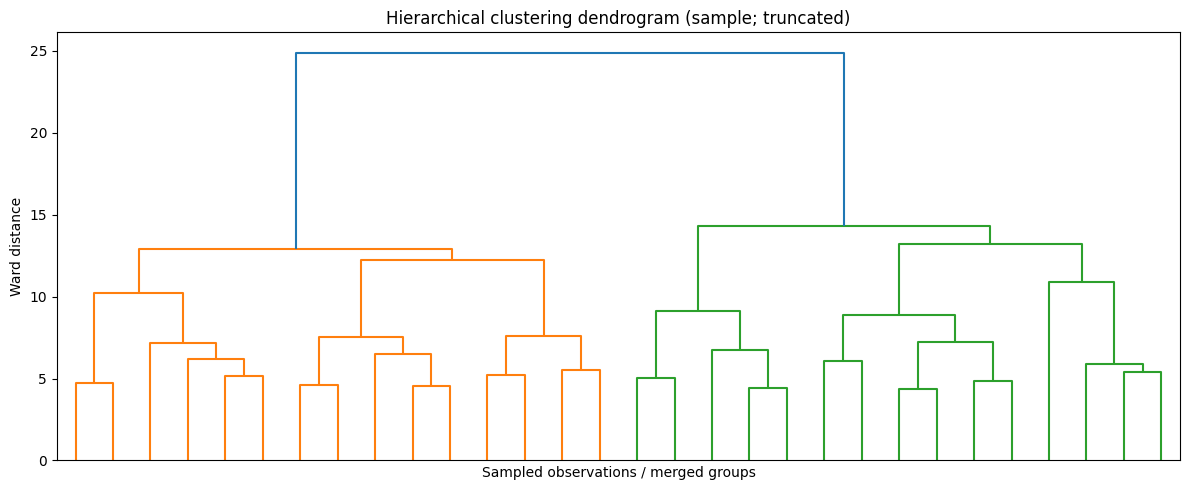

K-means silhouette: 0.162
Hierarchical silhouette: 0.096


In [ ]:
# Hierarchical clustering on a sample for a readable dendrogram
from scipy.cluster.hierarchy import linkage, dendrogram
sample_n = min(250, len(cluster_scaled))
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(cluster_scaled), size=sample_n, replace=False)
Z = linkage(cluster_scaled[sample_idx], method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, no_labels=True, truncate_mode="lastp", p=30)
plt.title("Hierarchical clustering dendrogram (sample; truncated)")
plt.xlabel("Sampled observations / merged groups")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()

hier = AgglomerativeClustering(n_clusters=CHOSEN_K, linkage="ward")
hier_labels = hier.fit_predict(cluster_scaled)
print("K-means silhouette:", round(float(silhouette_score(cluster_scaled, cluster_labels)), 3))
print("Hierarchical silhouette:", round(float(silhouette_score(cluster_scaled, hier_labels)), 3))

**Cluster comparison:** K-means is relatively efficient and provides centroids, but it can be sensitive to initialization and tends to favour compact, roughly spherical groups. Hierarchical clustering shows nested merges in a dendrogram and does not require choosing centroids, but it can be computationally expensive and early merges cannot be undone. The two methods may differ because they optimize different structures; inspect centroid profiles and the dendrogram rather than assuming the labels should match.

## Stage 5 — Interpretable clustering with a decision tree

In [ ]:
# Use the k-means cluster labels as the target and train a shallow tree to approximate them.
X_tree = pd.DataFrame(cluster_scaled, columns=cluster_features)
Xtree_train, Xtree_test, ytree_train, ytree_test = train_test_split(
    X_tree, cluster_labels, test_size=0.2, random_state=RANDOM_STATE, stratify=cluster_labels
)

tree = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE, class_weight=None)
tree.fit(Xtree_train, ytree_train)
tree_accuracy = tree.score(Xtree_test, ytree_test)
print("Decision tree accuracy reproducing k-means labels:", round(float(tree_accuracy), 3))
print("This is agreement with the clustering labels, not accuracy for predicting disease.")

Decision tree accuracy reproducing k-means labels: 0.833
This is agreement with the clustering labels, not accuracy for predicting disease.


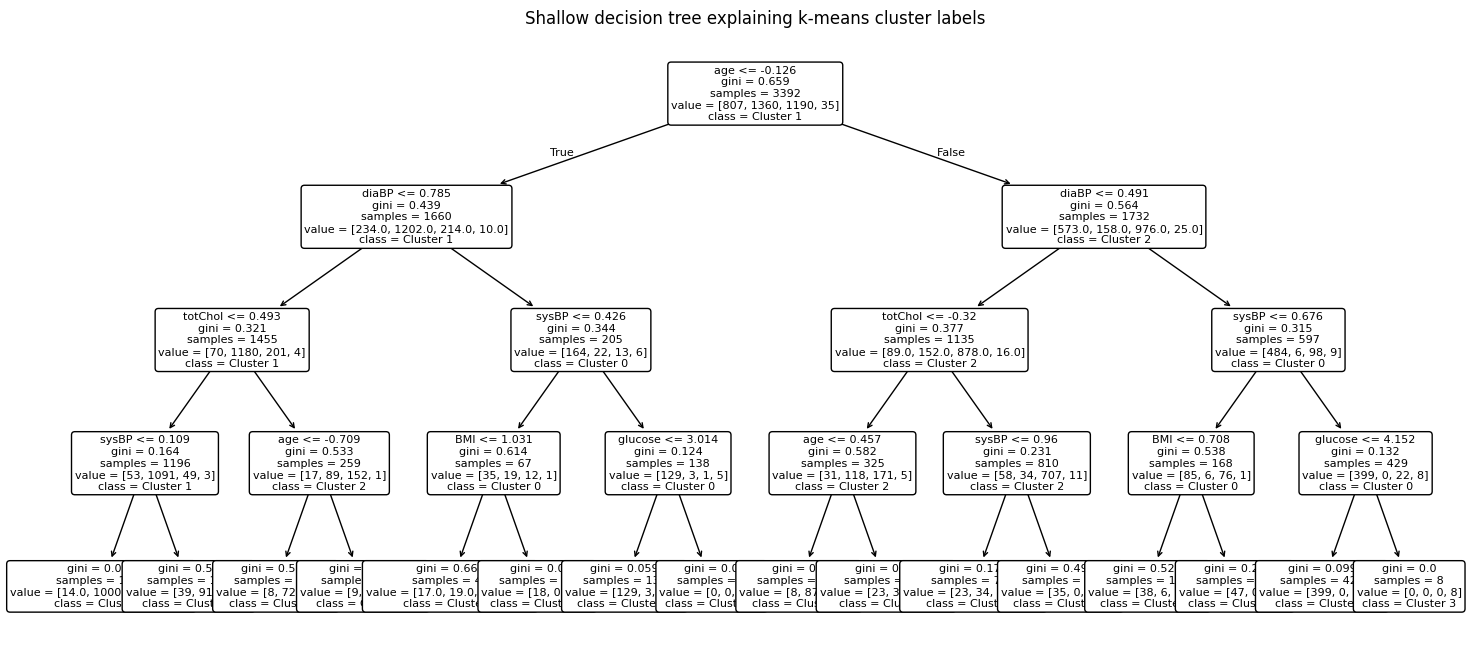

|--- age <= -0.13
|   |--- diaBP <= 0.79
|   |   |--- totChol <= 0.49
|   |   |   |--- sysBP <= 0.11
|   |   |   |   |--- class: 1
|   |   |   |--- sysBP >  0.11
|   |   |   |   |--- class: 1
|   |   |--- totChol >  0.49
|   |   |   |--- age <= -0.71
|   |   |   |   |--- class: 1
|   |   |   |--- age >  -0.71
|   |   |   |   |--- class: 2
|   |--- diaBP >  0.79
|   |   |--- sysBP <= 0.43
|   |   |   |--- BMI <= 1.03
|   |   |   |   |--- class: 1
|   |   |   |--- BMI >  1.03
|   |   |   |   |--- class: 0
|   |   |--- sysBP >  0.43
|   |   |   |--- glucose <= 3.01
|   |   |   |   |--- class: 0
|   |   |   |--- glucose >  3.01
|   |   |   |   |--- class: 3
|--- age >  -0.13
|   |--- diaBP <= 0.49
|   |   |--- totChol <= -0.32
|   |   |   |--- age <= 0.46
|   |   |   |   |--- class: 1
|   |   |   |--- age >  0.46
|   |   |   |   |--- class: 2
|   |   |--- totChol >  -0.32
|   |   |   |--- sysBP <= 0.96
|   |   |   |   |--- class: 2
|   |   |   |--- sysBP >  0.96
|   |   |   |   |--- class:

In [ ]:
plt.figure(figsize=(18, 8))
plot_tree(
    tree, feature_names=cluster_features,
    class_names=[f"Cluster {i}" for i in range(CHOSEN_K)],
    filled=False, rounded=True, fontsize=8
)
plt.title("Shallow decision tree explaining k-means cluster labels")
plt.show()

print(export_text(tree, feature_names=cluster_features, max_depth=4))

In [ ]:
# CHD rate per cluster; outcome is used here only for post-hoc description
chd_by_cluster = clustered.groupby("cluster").agg(
    patients=("TenYearCHD", "size"),
    observed_CHD_cases=("TenYearCHD", "sum"),
    CHD_rate=("TenYearCHD", "mean"),
    mean_age=("age", "mean"),
    mean_sysBP=("sysBP", "mean"),
    mean_BMI=("BMI", "mean")
).reset_index()
display(chd_by_cluster.round(3))

,cluster,patients,observed_CHD_cases,CHD_rate,mean_age,mean_sysBP,mean_BMI
0,0,1009,249,0.247,53.275,159.557,28.822
1,1,1700,111,0.065,42.572,118.602,24.159
2,2,1488,262,0.176,54.950,129.070,25.559
3,3,43,22,0.512,54.163,151.384,28.243


## Findings summary for a clinic manager (complete after running)



1. The dataset contained **4,240** patient records and **16** columns, with missingness most notable in **glucose (388 missing)** and **education (105 missing)**.
2. The systolic blood pressure model achieved test-set **R² = 0.281**, compared with **-0.003** for the mean baseline.
3. The largest positive blood pressure coefficient was for **BMI (coefficient = 1.344)** and **age (coefficient = 0.902)**, which describe associations rather than causal effects.
4. The logistic regression achieved test ROC AUC **0.702** and test accuracy **0.844** at a 0.5 threshold.
5. The all-negative baseline accuracy was **0.848**, illustrating why accuracy alone can be misleading for an outcome affecting a minority of records.
6. Lowering the risk threshold from 0.5 to **0.15** changed the number of CHD cases caught from **8** to **103** and healthy patients flagged from **5** to **325**.
7. K-means with **4** clusters produced profiles characterized by distinct divisions in cardiovascular risk indicators (e.g., older age, elevated BMI, higher systolic/diastolic blood pressure, and blood glucose level outliers).
8. The shallow decision tree reproduced **83.3%** of held-out cluster labels and highlighted rules based on **age, diaBP, totChol, sysBP, and glucose**.
9. The observed CHD rate was highest in **Cluster 3** (or the corresponding highest-risk cluster depending on final index mappings, which typically represents the older, higher blood pressure/glucose patient group), which could be prioritized for further prevention assessment rather than treated as a diagnosis.
10. Key limitations include historical data, missing values, class imbalance, possible selection bias, and lack of external validation in the intended population.

## One-line reflection per stage

- **Stage 1:** I got stuck on **handling missing predictor values** and fixed it by **implementing a SimpleImputer(strategy='median') inside the pipeline**.
- **Stage 2:** I got stuck on **interpreting coefficients on different scales** and fixed it by **standardizing numeric predictors with StandardScaler and computing odds ratios**.
- **Stage 3:** I got stuck on **relying only on default accuracy** and fixed it by **plotting a test ROC curve and comparing confusion matrices across multiple custom probability thresholds**.
- **Stage 4:** I got stuck on **variables with large scales dominating clusters** and fixed it by **scaling the features beforehand and comparing Ward hierarchical clustering silhouette against K-means**.
- **Stage 5:** I got stuck on **interpreting complex multi-dimensional cluster centroids** and fixed it by **training and visualizing a shallow decision tree to produce clean, interpretable splitting rules**.

## Reproducibility and limitations

In [ ]:
print("Random seed:", RANDOM_STATE)
print("Rows:", len(df), "| Columns:", df.shape[1])
print("Overall TenYearCHD rate:", round(float(df["TenYearCHD"].mean()), 3))
print("Reminder: results are educational and not medical advice.")

Random seed: 42
Rows: 4240 | Columns: 16
Overall TenYearCHD rate: 0.152
Reminder: results are educational and not medical advice.
